# Clustering Historical Earnings Patterns

## Clustering Analysis

I used clustering to explore whether historical earnings patterns formed meaningful groups. I compared K-Means, Agglomerative Clustering and DBSCAN using the same sample of 4,000 observations.

I evaluated the clustering results using separation metrics and PCA visualizations. I excluded the 2024 holdout from this analysis.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import Image, display
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CLUSTERING_RESULTS_DIR = PROJECT_ROOT / "results" / "clustering"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

# loads the saved clustering comparison
comparison_path = CLUSTERING_RESULTS_DIR / "algorithm_comparison.json"

with comparison_path.open(encoding="utf-8") as file:
    clustering_results = json.load(file)

print("Clustering results loaded successfully.")
print(f"Observations: {clustering_results['sample_count']:,}")
print(f"Features: {clustering_results['feature_count']}")
print(f"Holdout used: {clustering_results['holdout_used']}")

Clustering results loaded successfully.
Observations: 4,000
Features: 39
Holdout used: False


### K-Means Clustering

I used K-Means to examine whether observations with similar historical earnings patterns formed distinct groups. I tested values of \(k\) from 2 to 8 and compared their clustering scores.

The best silhouette score came from \(k=2\) so I used two clusters for the rest of the analysis. The silhouette score was 0.221, suggesting that the groups have some structure but are not strongly separated.

The first cluster contained 1,817 observations and the second contained 2,183. Their sizes were fairly similar so neither cluster dominated the sample.

In [2]:
kmeans_results = clustering_results["kmeans"]

kmeans_summary = pd.DataFrame(
    {
        "Metric": [
            "Number of clusters",
            "Silhouette score",
            "Calinski-Harabasz score",
            "Davies-Bouldin score",
        ],
        
        "Value": [
            kmeans_results["cluster_count"],
            kmeans_results["silhouette_score"],
            kmeans_results["calinski_harabasz_score"],
            kmeans_results["davies_bouldin_score"],
        ],
    }
)

display(kmeans_summary.round(4))

cluster_sizes = pd.DataFrame(
    [
        {
            "Cluster": int(cluster),
            "Observations": count,
            "Percentage": 100 * count / clustering_results["sample_count"],
        }
        for cluster, count in kmeans_results["cluster_sizes"].items()
    ]
)

cluster_sizes = cluster_sizes.sort_values("Cluster")

display(cluster_sizes.round(2))

,Metric,Value
0,Number of clusters,2.0000
1,Silhouette score,0.2208
2,Calinski-Harabasz score,1259.8459
3,Davies-Bouldin score,1.6581


,Cluster,Observations,Percentage
0,0,1817,45.42
1,1,2183,54.58


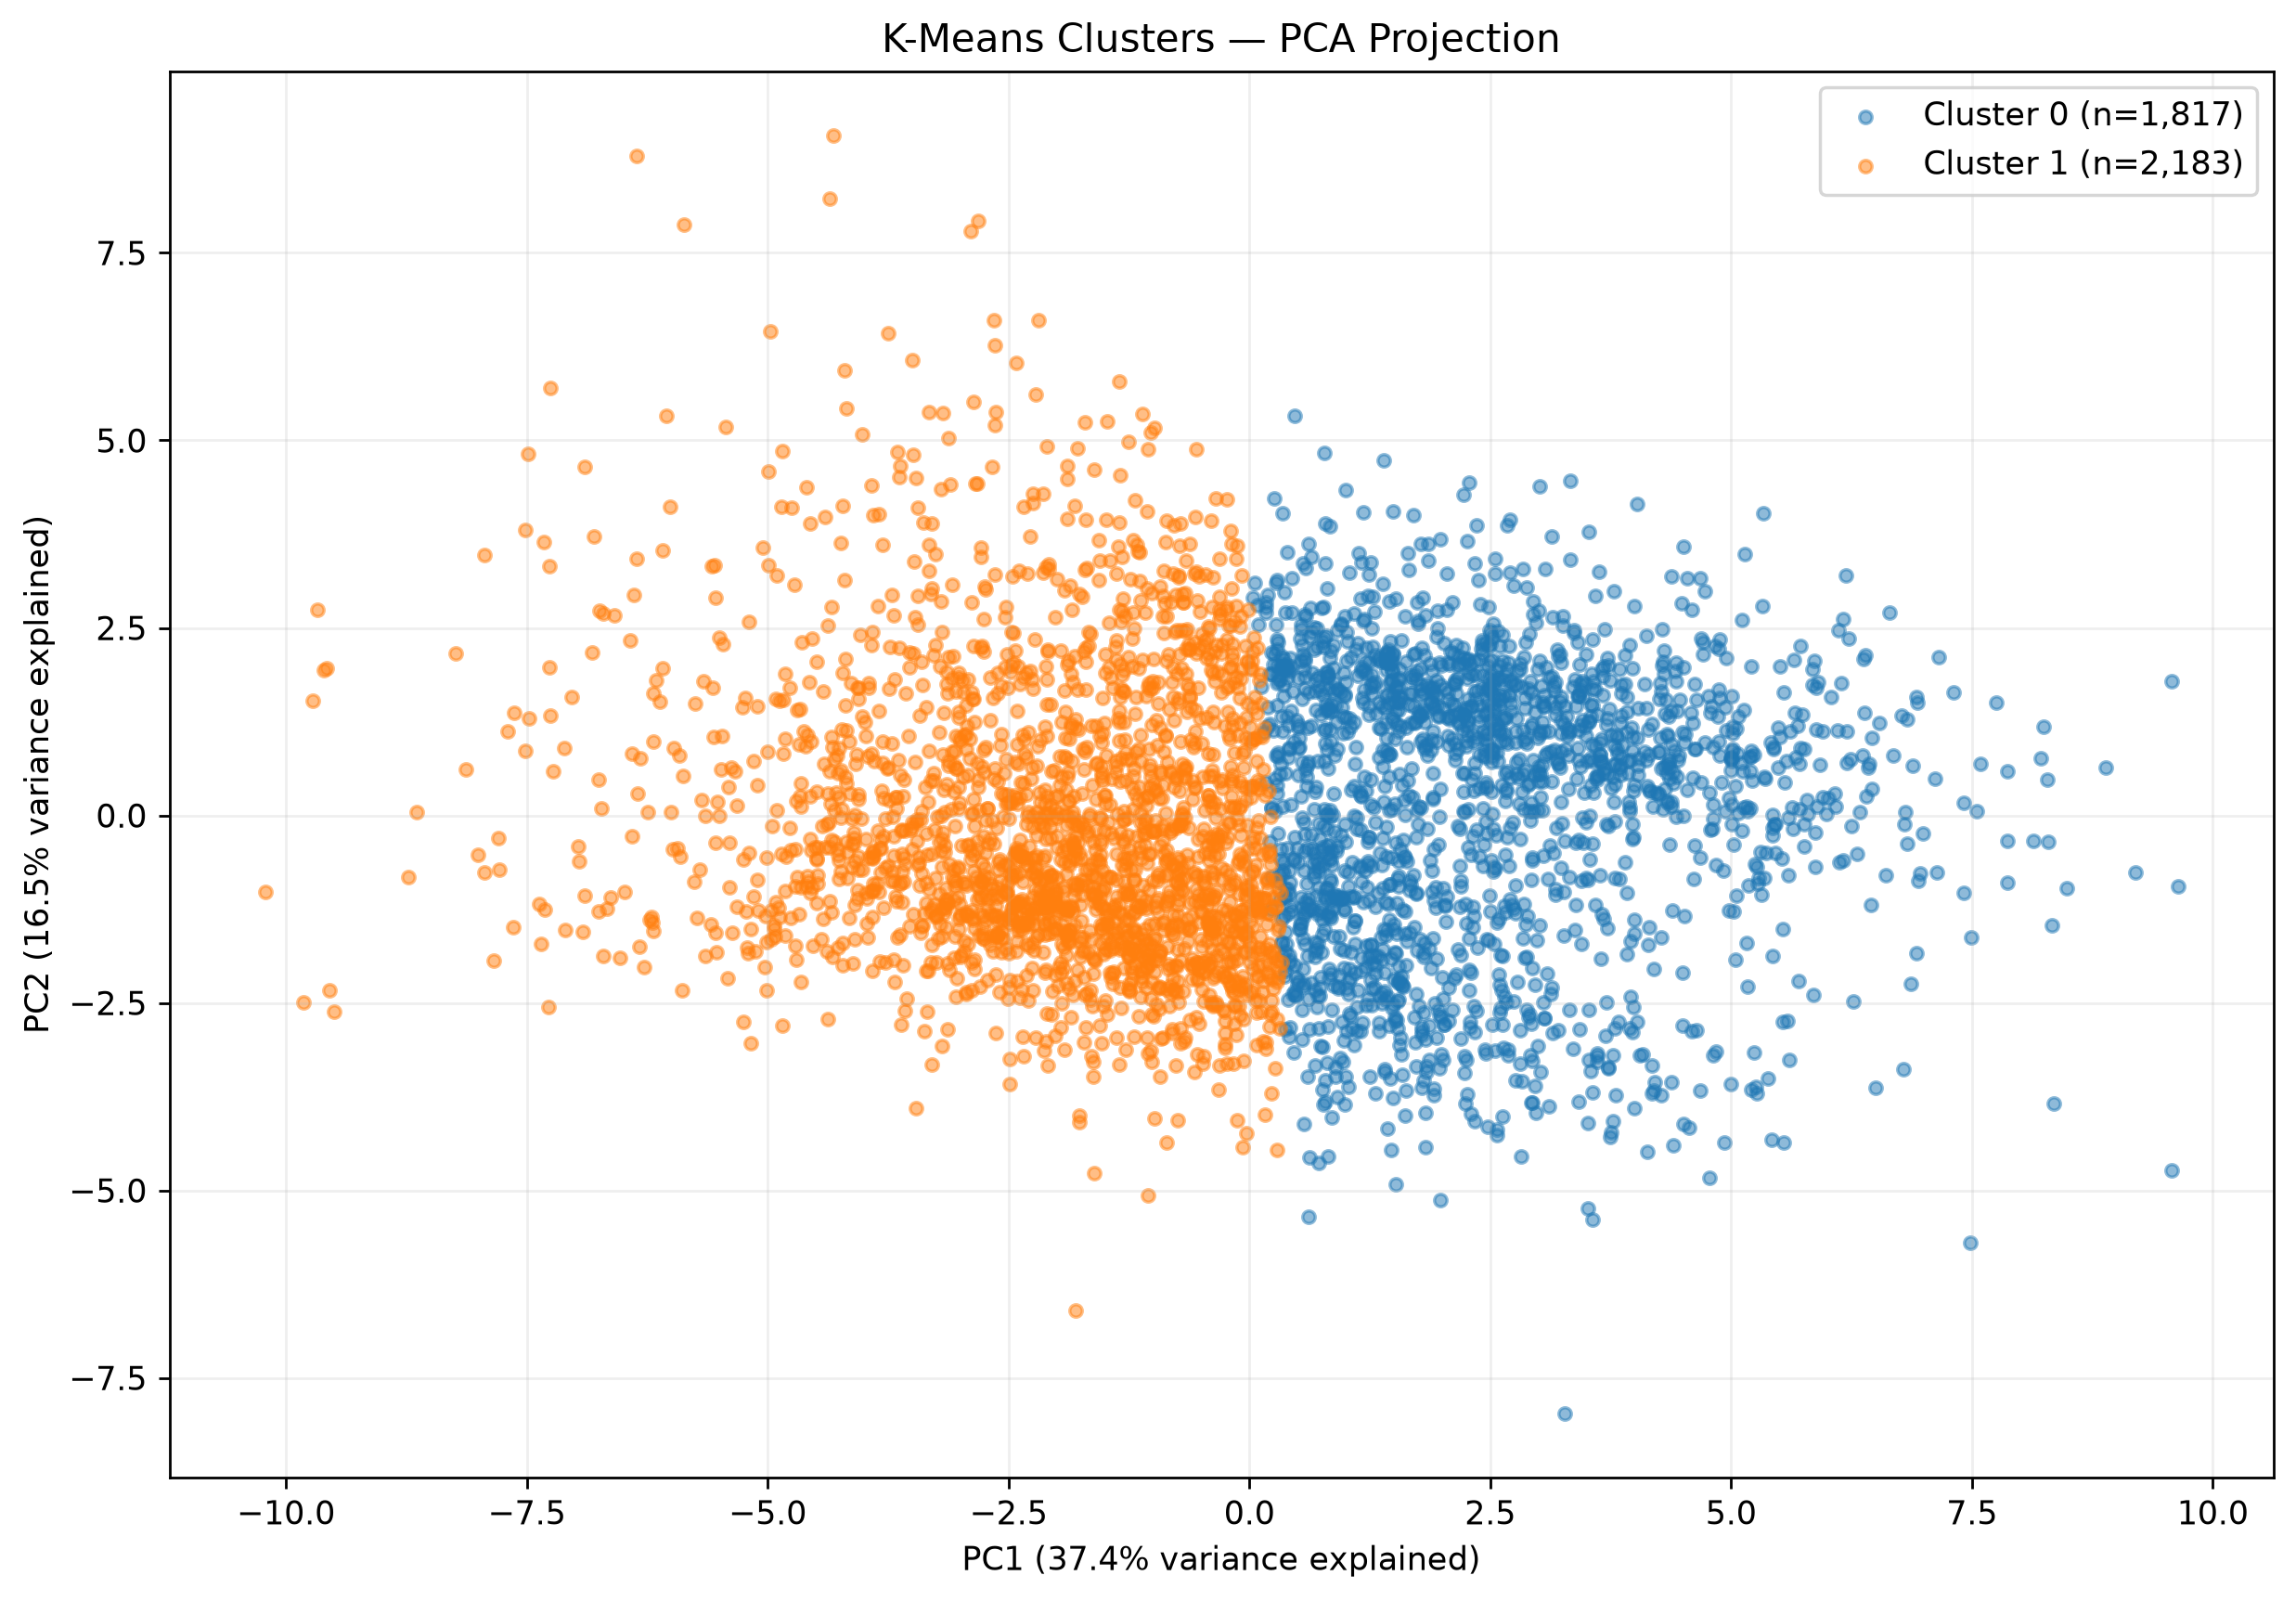

In [3]:
from IPython.display import Image, display

kmeans_figure = FIGURES_DIR / "kmeans_pca_k2.png"

display(Image(filename=str(kmeans_figure)))

#### PCA Visualization

I used PCA to reduce the 39 transformed features to two dimensions so I could visualize the K-Means clusters.

The first principal component explained 37.43% of the variance, while the second explained 16.54%. Together, they captured approximately 53.97% of the variation in the data.

I used PCA only for visualization. The clustering itself was performed using all 39 transformed features.

The relatively low silhouette score of 0.221 suggests that the two groups are not strongly separated in the original feature space. I would therefore be cautious about treating them as distinct types of companies or earnings behaviour.

In [4]:
kmeans_sweep_path = CLUSTERING_RESULTS_DIR / "kmeans_sweep.json"

with kmeans_sweep_path.open(encoding="utf-8") as file:
    kmeans_sweep = json.load(file)

sweep_results = []

for result in kmeans_sweep["evaluations"]:
    sweep_results.append(
        {
            "Clusters": result["cluster_count"],
            "Silhouette": result["silhouette_score"],
            "Calinski-Harabasz": result["calinski_harabasz_score"],
            "Davies-Bouldin": result["davies_bouldin_score"],
        }
    )

kmeans_sweep_table = pd.DataFrame(sweep_results)
kmeans_sweep_table = kmeans_sweep_table.sort_values("Clusters")

display(kmeans_sweep_table.round(3))

,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.221,1259.846,1.658
1,3,0.166,956.001,1.801
2,4,0.152,826.643,1.740
3,5,0.151,723.311,1.819
4,6,0.137,650.163,1.858
5,7,0.133,590.357,1.813
6,8,0.123,547.533,1.846


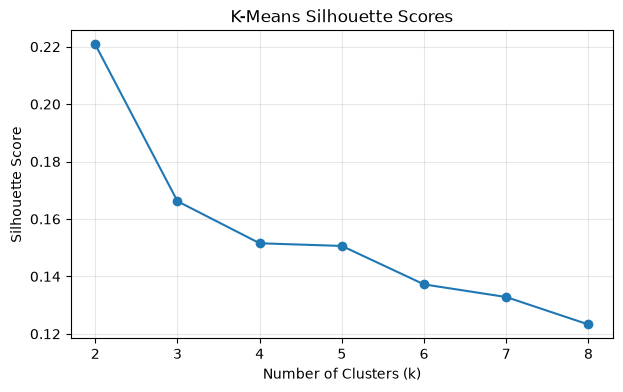

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    kmeans_sweep_table["Clusters"],
    kmeans_sweep_table["Silhouette"],
    marker="o",
)

plt.title("K-Means Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(kmeans_sweep_table["Clusters"])
plt.grid(alpha=0.3)

plt.show()

In [6]:
pca_results_path = CLUSTERING_RESULTS_DIR / "kmeans_pca_k2.json"

with pca_results_path.open(encoding="utf-8") as file:
    pca_results = json.load(file)

explained_variance = pca_results["pca"]["explained_variance_ratio"]

pca_table = pd.DataFrame(
    {
        "Principal Component": ["PC1", "PC2"],
        "Explained Variance (%)": [variance * 100 for variance in explained_variance],
    }
)

display(pca_table.round(2))

print(
    f"Total explained variance: "
    f"{pca_results['pca']['total_explained_variance'] * 100:.2f}%"
)

,Principal Component,Explained Variance (%)
0,PC1,37.43
1,PC2,16.54


Total explained variance: 53.97%


In [7]:
kmeans_profile_path = CLUSTERING_RESULTS_DIR / "kmeans_profile_k2.csv"

kmeans_profile = pd.read_csv(kmeans_profile_path)

assert kmeans_profile["samples"].sum() == clustering_results["sample_count"]

display(kmeans_profile.round(3))

,cluster,samples,median_beat_rate4,median_beat_streak4,median_surprise_mean4,median_surprise_std4,median_actual_eps_lag1
0,0,1817,0.75,3.0,0.071,0.075,0.84
1,1,2183,0.50,0.0,-0.003,0.076,-0.06


#### K-Means Cluster Profiles

I compared the historical earnings features within each cluster to understand what separated the groups. Cluster 0 had a median historical beat rate of 0.75 and a median beat streak of 3. Cluster 1 had a lower median beat rate of 0.50 and a median streak of 0.

This suggests that K-Means separated observations partly according to their recent earnings performance. Cluster 0 generally had stronger historical earnings-beat patterns, while cluster 1 contained observations with less consistent beat histories.

However, these groups describe past earnings behaviour. They do not establish whether an observation will beat expectations in its next earnings announcement.

#### Selecting the Number of Clusters

I compared K-Means configurations with 2 to 8 clusters. I used the silhouette score to measure how well the observations were grouped along with the Calinski–Harabasz and Davies–Bouldin scores.

The two-cluster configuration performed best across all three metrics. It achieved the highest silhouette score (0.221) and the lowest Davies–Bouldin score (1.658). I therefore selected \(k=2\) for the final K-Means analysis.

The silhouette scores were calculated using 1,000 sampled observations from the 4,000-observation clustering dataset.

Despite two clusters performing the best, the silhouette score is relatively low which suggests that the historical earnings patterns have some structure but the groups are not clearly separated.


### Agglomerative Clustering

I also tested Agglomerative Clustering to see whether a different clustering method would identify similar groups.

I used Ward linkage with Euclidean distance, which combines clusters based on how much their within-cluster variation increases. I tested between 2 and 8 clusters, using the same 4,000 observations and 39 transformed features as K-Means.

I compared the silhouette, Calinski–Harabasz, and Davies–Bouldin scores to decide which number of clusters worked best.


In [8]:
agglomerative_sweep_path = CLUSTERING_RESULTS_DIR / "agglomerative_sweep.json"

with agglomerative_sweep_path.open(encoding="utf-8") as file:
    agglomerative_sweep = json.load(file)

agglomerative_rows = []

for result in agglomerative_sweep["evaluations"]:
    agglomerative_rows.append(
        {
            "Clusters": result["cluster_count"],
            "Silhouette": result["silhouette_score"],
            "Calinski-Harabasz": result["calinski_harabasz_score"],
            "Davies-Bouldin": result["davies_bouldin_score"],
        }
    )

agglomerative_table = pd.DataFrame(agglomerative_rows)
agglomerative_table = agglomerative_table.sort_values("Clusters")

display(agglomerative_table.round(3))

,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.199,995.111,1.651
1,3,0.111,776.737,2.222
2,4,0.095,688.290,1.963
3,5,0.101,606.945,1.950
4,6,0.101,542.128,2.147
5,7,0.088,489.734,2.152
6,8,0.081,452.610,2.208


#### Agglomerative Cluster Profiles

I examined the historical earnings features within the two clusters to see what distinguished them.

Cluster 1 contained observations with stronger historical earnings results. Its median beat rate was 1.00, and its median beat streak was 4. Cluster 0 had a median beat rate of 0.50 and a streak of 1.

This suggests that Agglomerative Clustering identified a smaller group with consistently stronger recent earnings performance. However, the clusters still had a relatively low silhouette score, so I would be cautious about treating them as clearly separate groups.

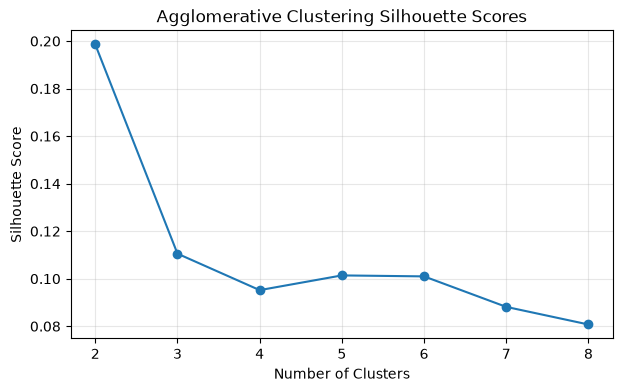

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(
    agglomerative_table["Clusters"],
    agglomerative_table["Silhouette"],
    marker="o",
)

plt.title("Agglomerative Clustering Silhouette Scores")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(agglomerative_table["Clusters"])
plt.grid(alpha=0.3)

plt.show()

In [10]:
agglomerative_results = clustering_results["agglomerative"]

agglomerative_summary = pd.DataFrame(
    {
        "Metric": [
            "Number of clusters",
            "Silhouette score",
            "Calinski-Harabasz score",
            "Davies-Bouldin score",
        ],
        
        "Value": [
            agglomerative_results["cluster_count"],
            agglomerative_results["silhouette_score"],
            agglomerative_results["calinski_harabasz_score"],
            agglomerative_results["davies_bouldin_score"],
        ],
    }
)

display(agglomerative_summary.round(4))

cluster_sizes = pd.DataFrame(
    [
        {
            "Cluster": int(cluster),
            "Observations": count,
            "Percentage": 100 * count / clustering_results["sample_count"],
        }
        
        for cluster, count in agglomerative_results["cluster_sizes"].items()
    ]
)

display(cluster_sizes.sort_values("Cluster").round(2))

,Metric,Value
0,Number of clusters,2.0000
1,Silhouette score,0.1986
2,Calinski-Harabasz score,995.1106
3,Davies-Bouldin score,1.6506


,Cluster,Observations,Percentage
0,0,2884,72.1
1,1,1116,27.9


In [11]:
agglomerative_profile_path = CLUSTERING_RESULTS_DIR / "agglomerative_profile_k2.csv"

agglomerative_profile = pd.read_csv(agglomerative_profile_path)

assert agglomerative_profile["samples"].sum() == clustering_results["sample_count"]

display(agglomerative_profile.round(3))

,cluster,samples,median_beat_rate4,median_beat_streak4,median_surprise_mean4,median_surprise_std4,median_actual_eps_lag1
0,0,2884,0.5,1.0,0.008,0.069,0.07
1,1,1116,1.0,4.0,0.102,0.090,1.16


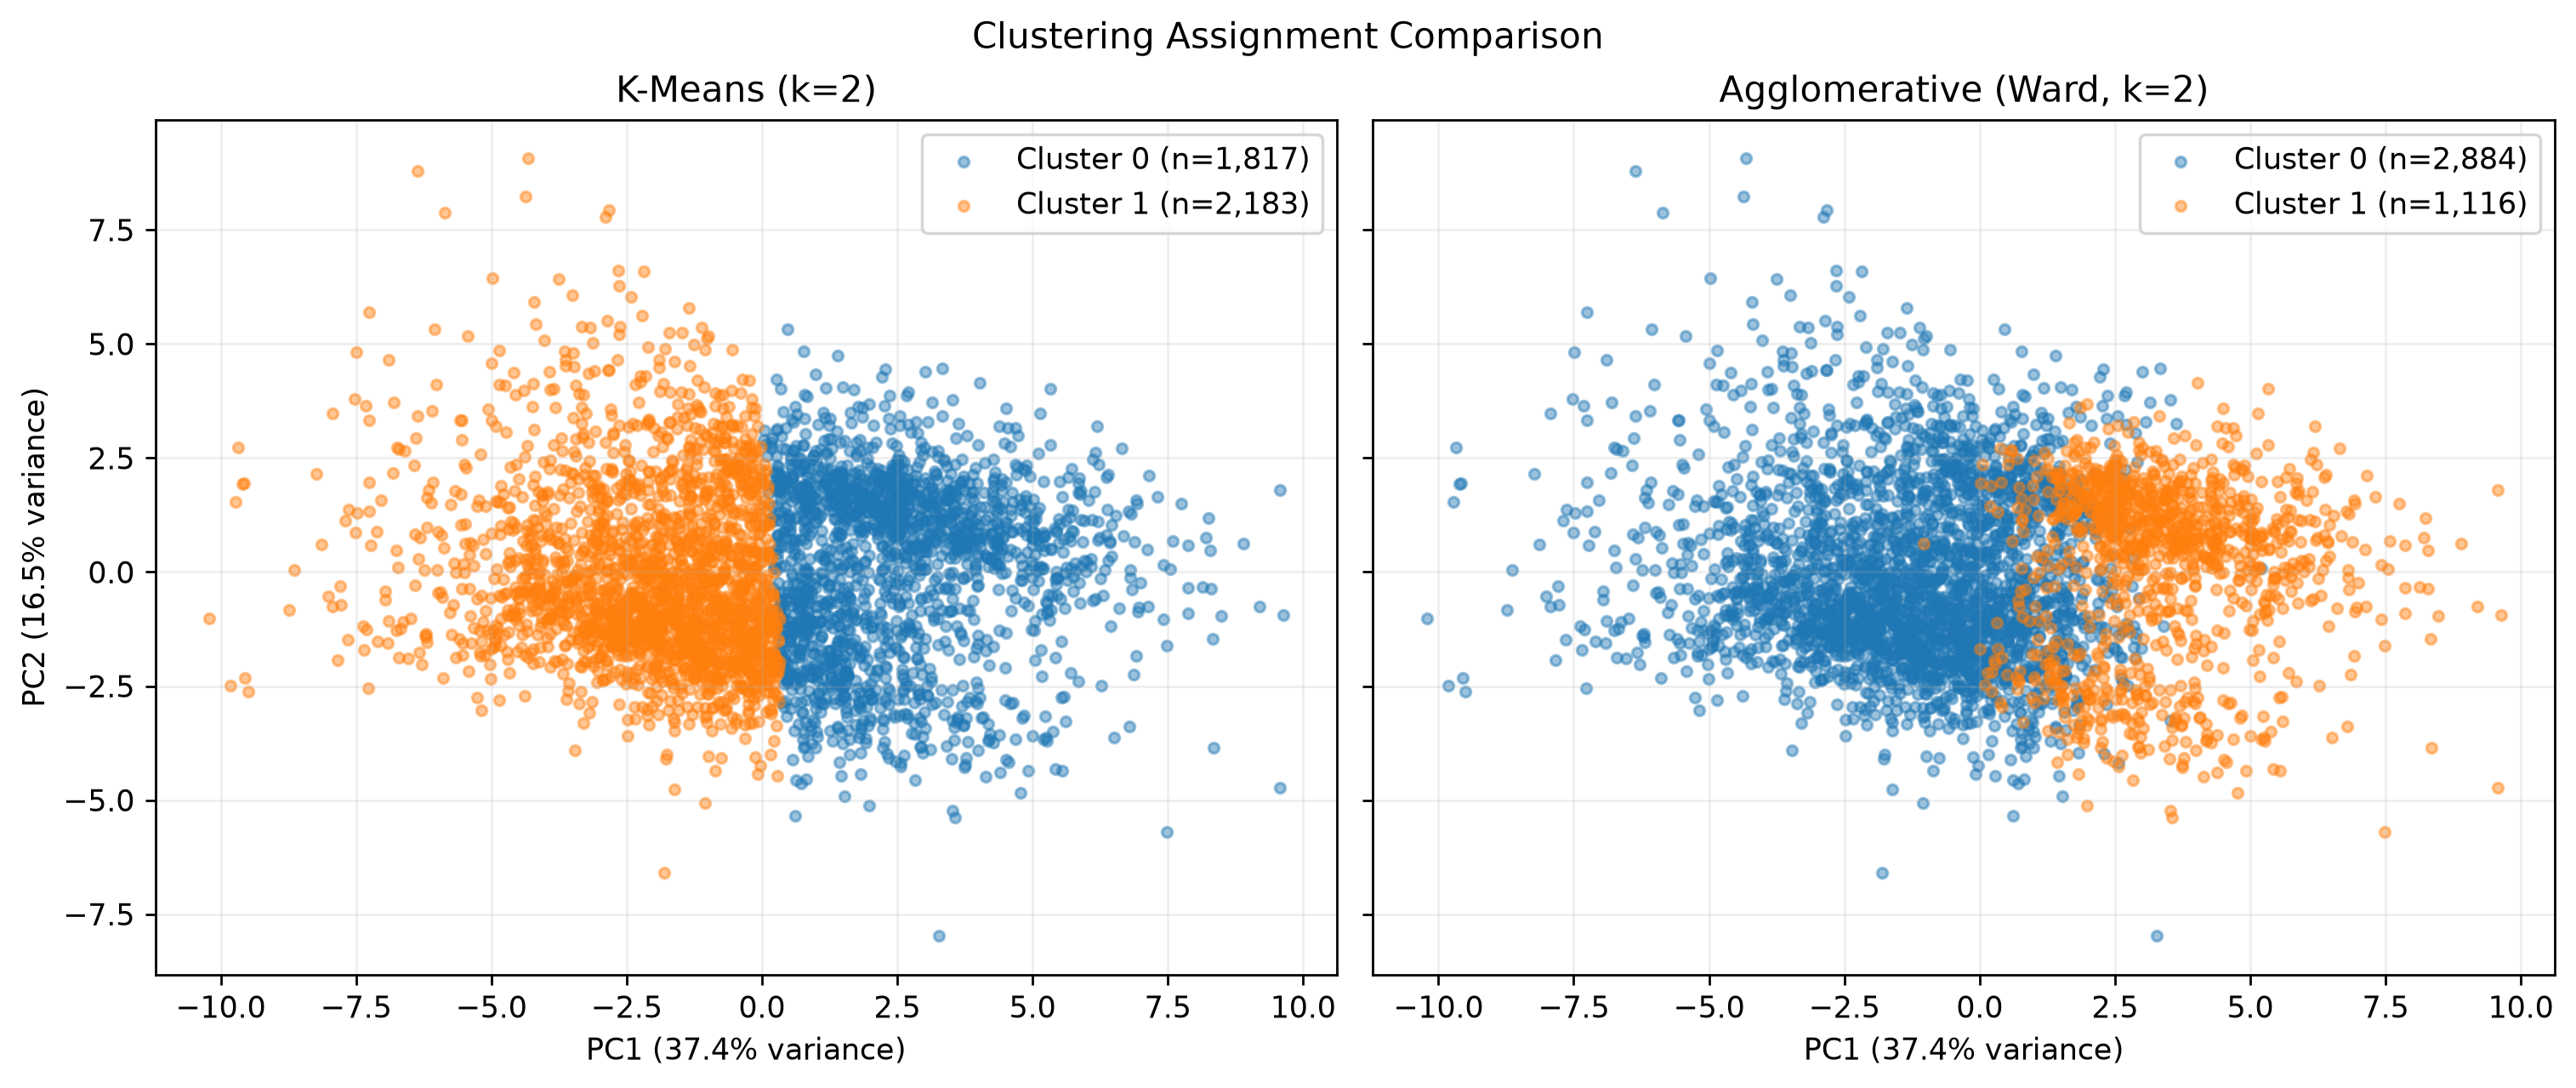

In [12]:
comparison_figure = FIGURES_DIR / "kmeans_vs_agglomerative_pca.png"

display(Image(filename=str(comparison_figure)))

#### Agglomerative Clustering Results

The two-cluster configuration achieved the highest silhouette score among the values I tested with a score of 0.199. The clusters were less evenly distributed than the K-Means results. Cluster 0 contained 2,884 observations and cluster 1 contained 1,116.

The silhouette score was slightly lower than K-Means (0.221) but the Davies–Bouldin score was marginally better. This suggests that neither method was clearly superior across every evaluation metric.

I also compared their PCA visualizations to examine how the cluster assignments differed. PCA was used only to display the results in two dimensions.

### DBSCAN Clustering

I also tested DBSCAN to see whether the historical earnings data contained groups of densely packed observations.

Unlike K-Means and Agglomerative Clustering DBSCAN does not require me to choose the number of clusters beforehand. Instead, it uses two parameters:

- **eps:** The maximum distance between nearby observations.
- **min_samples:** The minimum number of nearby observations required to form a dense region.

DBSCAN can also label observations as noise when they fall outside the identified dense regions.

I tested eight parameter combinations using the same 4,000 observations and 39 transformed features as the other clustering methods.

In [13]:
dbscan_sweep_path = CLUSTERING_RESULTS_DIR / "dbscan_sweep.json"

with dbscan_sweep_path.open(encoding="utf-8") as file:
    dbscan_sweep = json.load(file)


dbscan_table = pd.DataFrame(dbscan_sweep["evaluations"])

dbscan_table["Noise (%)"] = dbscan_table["noise_fraction"] * 100

display(
    dbscan_table[
        ["eps", "min_samples", "cluster_count", "noise_samples", "Noise (%)"]
    ].round(2)
)

,eps,min_samples,cluster_count,noise_samples,Noise (%)
0,2.26,10,1,1222,30.55
1,2.65,10,1,666,16.65
2,3.23,10,1,292,7.30
3,4.28,10,1,67,1.68
4,2.72,40,1,902,22.55
5,3.17,40,1,453,11.32
6,3.88,40,1,167,4.18
7,5.08,40,1,38,0.95


In [14]:
dbscan_results = clustering_results["dbscan"]

dbscan_summary = pd.DataFrame(
    {
        "Metric": [
            "Configurations tested",
            "Number of non-noise clusters",
            "Minimum noise percentage",
            "Maximum noise percentage",
            "Valid silhouette results",
        ],
        
        "Value": [
            dbscan_results["configurations_tested"],
            ", ".join(str(count) for count in dbscan_results["cluster_counts"]),
            f"{dbscan_results['minimum_noise_fraction'] * 100:.2f}%",
            f"{dbscan_results['maximum_noise_fraction'] * 100:.2f}%",
            dbscan_results["valid_silhouette_results"],
        ],
    }
)

display(dbscan_summary)

,Metric,Value
0,Configurations tested,8
1,Number of non-noise clusters,1
2,Minimum noise percentage,0.95%
3,Maximum noise percentage,30.55%
4,Valid silhouette results,0


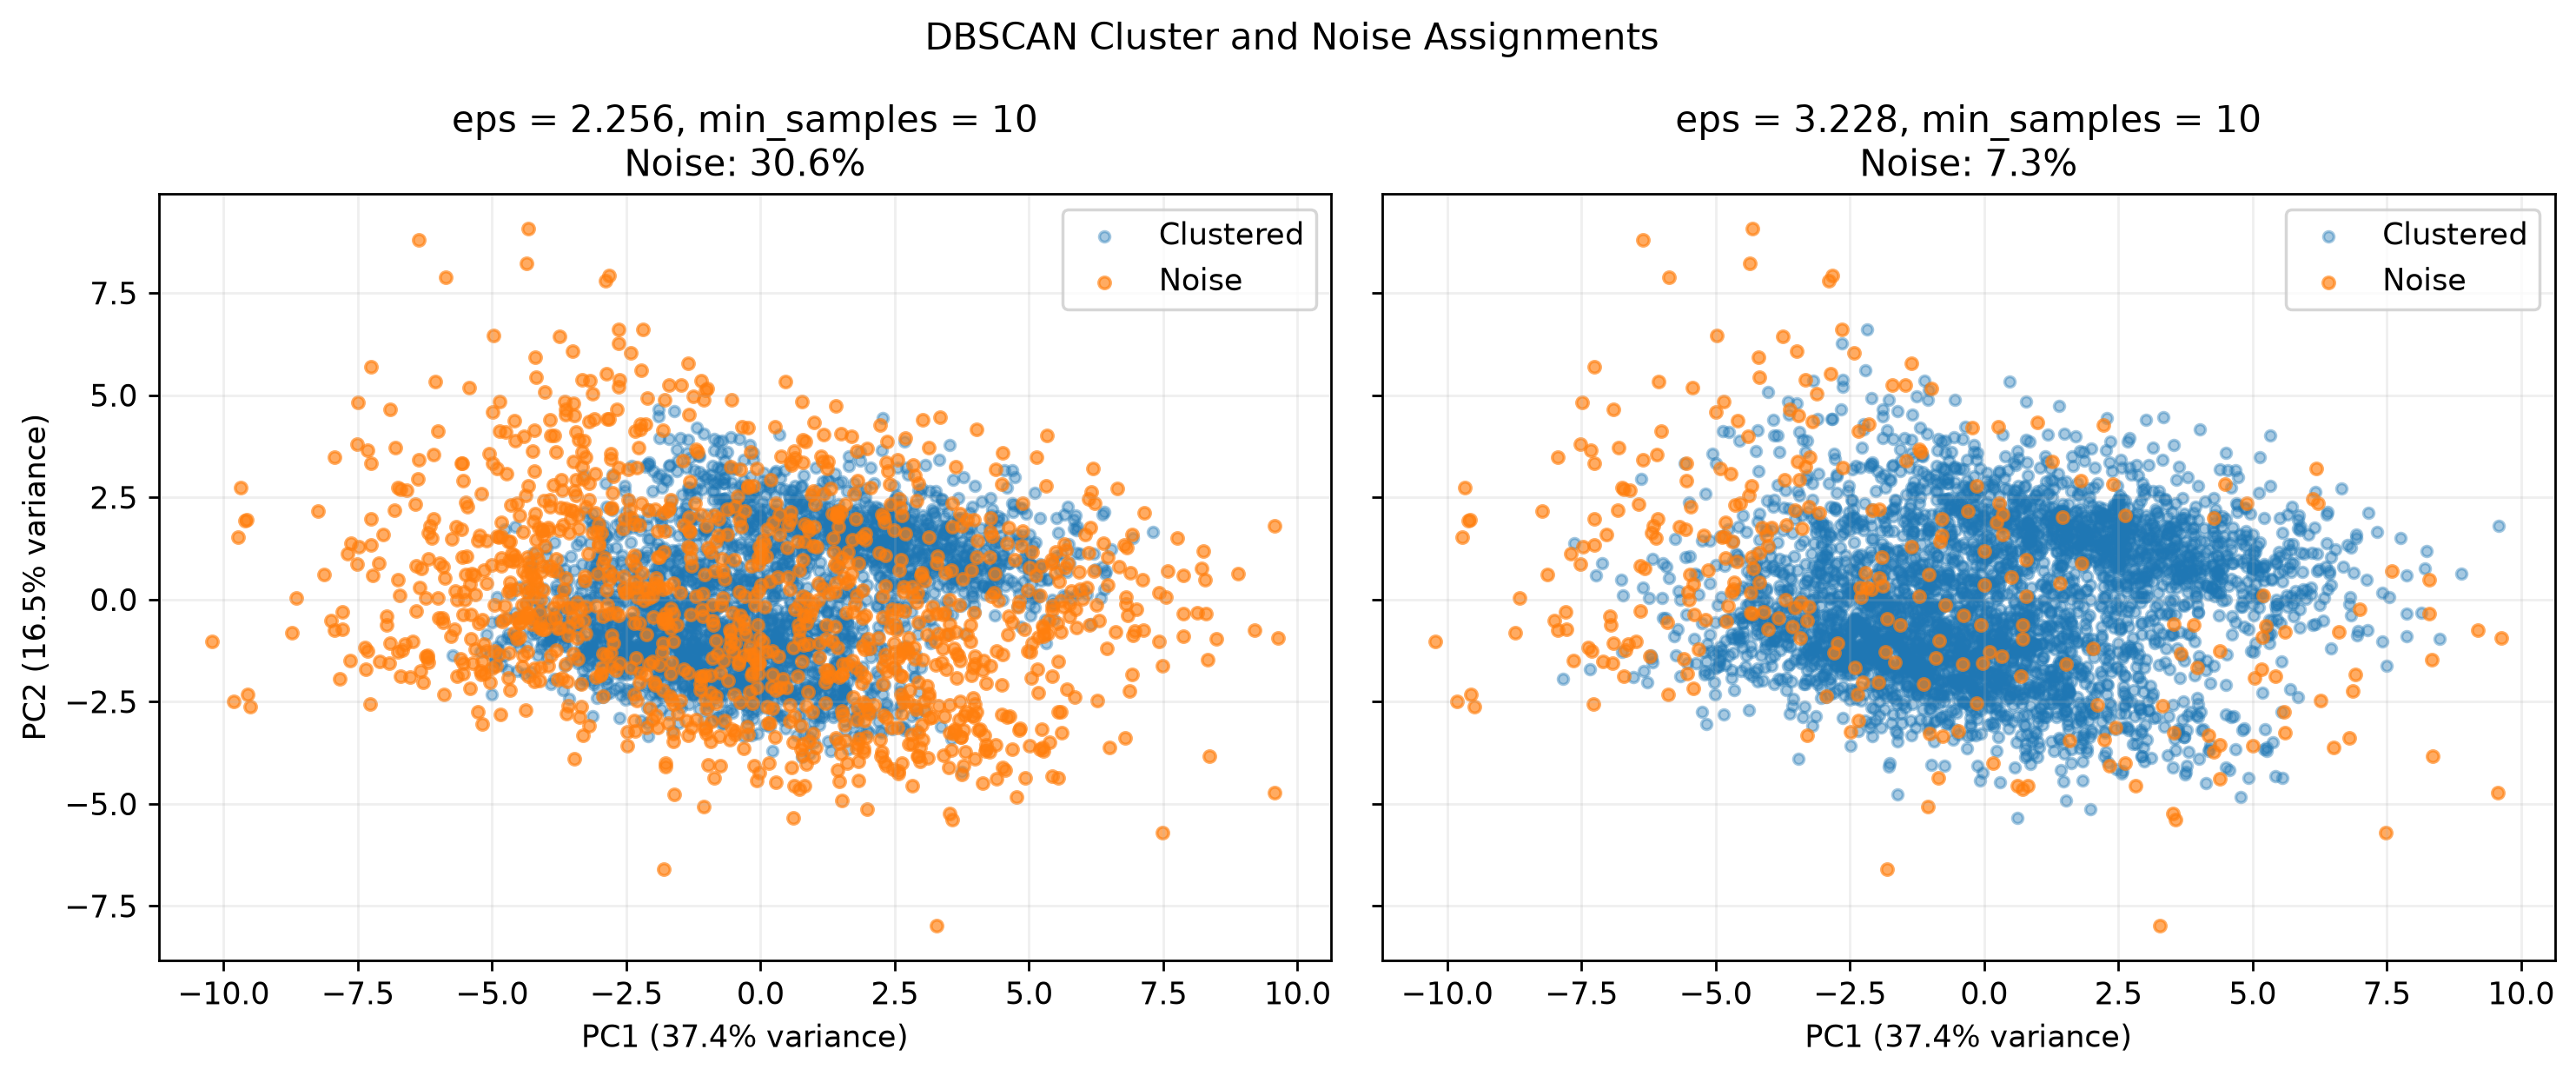

In [15]:
dbscan_figure = FIGURES_DIR / "dbscan_pca_noise_comparison.png"

display(Image(filename=str(dbscan_figure)))

#### DBSCAN Results

DBSCAN produced one main cluster in all eight parameter configurations I tested. The percentage of observations identified as noise varied from 0.95% to 30.55% depending on the parameter settings.

Because DBSCAN found only one non-noise cluster, I was unable to calculate a valid silhouette score for comparing separate density-based groups.

These results suggest that DBSCAN was more useful for identifying observations in sparse regions than for dividing the dataset into several clusters. The large difference in noise percentages also shows how sensitive DBSCAN was to its parameter settings.

### Comparing the Clustering Algorithms

I compared the three algorithms to see which method produced the clearest groups in the historical earnings data. K-Means and Agglomerative Clustering both produced two clusters. DBSCAN consistently identified one main cluster and treated some observations as noise.

I used the clustering scores to compare K-Means and Agglomerative Clustering. Since DBSCAN identified only one non-noise cluster its silhouette score was undefined.

In [16]:
comparison_rows = []

for algorithm, name in [
    ("kmeans", "K-Means"),
    ("agglomerative", "Agglomerative"),
]:
    results = clustering_results[algorithm]

    comparison_rows.append(
        {
            "Algorithm": name,
            "Clusters": results["cluster_count"],
            "Silhouette": results["silhouette_score"],
            "Calinski-Harabasz": results["calinski_harabasz_score"],
            "Davies-Bouldin": results["davies_bouldin_score"],
        }
    )

comparison_rows.append(
    {
        "Algorithm": "DBSCAN",
        "Clusters": 1,
        "Silhouette": None,
        "Calinski-Harabasz": None,
        "Davies-Bouldin": None,
    }
)

algorithm_table = pd.DataFrame(comparison_rows)

display(algorithm_table.round(3))

,Algorithm,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-Means,2,0.221,1259.846,1.658
1,Agglomerative,2,0.199,995.111,1.651
2,DBSCAN,1,NaN,NaN,NaN


#### Cluster Assignment Agreement

I also compared the K-Means and Agglomerative Clustering assignments using the Adjusted Rand Index (ARI) which allowed me to check whether the algorithms grouped the same observations together, despite them using different clustering methods.

In [17]:
partition_path = CLUSTERING_RESULTS_DIR / "partition_comparison.json"

with partition_path.open(encoding="utf-8") as file:
    partition_results = json.load(file)

agreement_score = partition_results["adjusted_rand_index"]

agreement_table = pd.DataFrame(
    partition_results["contingency_matrix"],
    index=["K-Means Cluster 0", "K-Means Cluster 1"],
    columns=["Agglomerative 0", "Agglomerative 1"],
)

assert agreement_table.to_numpy().sum() == clustering_results["sample_count"]

print(f"Adjusted Rand Index: {agreement_score:.3f}")

display(agreement_table)

Adjusted Rand Index: 0.408


,Agglomerative 0,Agglomerative 1
K-Means Cluster 0,711,1106
K-Means Cluster 1,2173,10


#### Interpreting the Results

The Adjusted Rand Index was 0.408 indicating some agreement between the two clustering methods. 

Most observations assigned to K-Means cluster 1 were placed in Agglomerative cluster 0. However, the observations in K-Means cluster 0 were divided between both Agglomerative clusters which suggests that the algorithms identified some similar structure, but disagreed on how to divide a substantial part of the dataset.

Overall, K-Means produced the highest silhouette score and Agglomerative Clustering had a slightly better Davies–Bouldin score. Neither method produced strongly separated groups. DBSCAN was more useful for identifying observations in sparse regions than for finding multiple clusters.

### Conclusion

I found some structure in the historical earnings data, although none of the algorithms produced strongly separated groups.

K-Means performed best on the silhouette score, achieving 0.221 with two clusters. The cluster profiles suggested that recent earnings beat rates and streaks helped distinguish the groups.

Agglomerative Clustering also identified differences in historical earnings performance. However, its cluster assignments only partially agreed with K-Means, with an Adjusted Rand Index of 0.408.

DBSCAN identified one main cluster across the parameter settings I tested. It was more useful for identifying observations in sparse regions than for separating the dataset into multiple groups.

Overall, clustering helped me understand differences in historical earnings behaviour. I treated these findings as exploratory because the cluster separation was relatively weak. I did not use cluster membership as a target label for the classification models.